# Aula 02 — Introdução ao ML e KDD · Conteúdo

**Unidade 1 — Introdução à Ciência de Dados e Python** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

## 🤖 Aula 02 — Introdução ao ML e KDD

Segunda aula da disciplina (semana de 24/08/2026). Você encontrará: o **livro da aula** com a teoria de Aprendizado de Máquina e do processo KDD, um **exemplo prático** — um classificador KNN construído do zero, em Python puro, aplicado aos dados das escolas do RN — e o **formulário avaliativo**.

---
## Tópicos de Estudo — Aula 02: Introdução ao ML e KDD

### Descrição

Conteúdo teórico da Aula 02, em formato de livro: paradigmas de Aprendizado de Máquina, o processo KDD, os conceitos de overfitting e underfitting, métricas de avaliação básicas e um exemplo prático de classificador construído do zero.

### 1. Capítulo 1 — Paradigmas de Aprendizado de Máquina

Aprendizado de Máquina (ML) é o subcampo da Ciência de Dados em que algoritmos aprendem padrões a partir de **exemplos**, em vez de seguirem regras explicitamente programadas. Os problemas de ML se organizam em três paradigmas principais.

#### Aprendizado Supervisionado

O algoritmo aprende a partir de exemplos **rotulados**: cada entrada vem acompanhada da resposta correta (o "rótulo" ou "target"). O objetivo é aprender uma função que generalize para exemplos novos, ainda não vistos.

- **Classificação:** o rótulo é uma categoria (ex.: escola de desempenho "alto", "médio" ou "baixo").
- **Regressão:** o rótulo é um valor numérico contínuo (ex.: prever a nota média de um aluno).

#### Aprendizado Não Supervisionado

Não há rótulos: o algoritmo busca **estrutura** nos dados por conta própria — grupos de exemplos semelhantes (clustering), redução de dimensionalidade ou padrões de associação. Ex.: agrupar escolas do RN por perfil de desempenho sem informar previamente categorias.

#### Aprendizado por Reforço

Um agente aprende por **tentativa e erro**, interagindo com um ambiente e recebendo recompensas ou penalidades por suas ações — usado em jogos, robótica e sistemas de recomendação adaptativos. Foge do escopo prático desta disciplina, mas é importante reconhecer o paradigma.

#### Onde estamos nesta disciplina?

Na Unidade 4 (Aprendizado de Máquina Aplicado) você praticará classificação, regressão e clustering com `scikit-learn`. Nesta aula, para entender os fundamentos, construiremos um classificador **do zero**, sem bibliotecas de ML — o KNN.

### 2. Capítulo 2 — O Processo KDD

**KDD** (Knowledge Discovery in Databases — Descoberta de Conhecimento em Bases de Dados) é o processo mais amplo do qual a Mineração de Dados é apenas uma etapa. Foi formalizado nos anos 1990 e continua sendo a base conceitual por trás de metodologias mais recentes, como o CRISP-DM (Capítulo 4 da Aula 01).

#### As cinco etapas do KDD

1.  **Seleção:** escolher, dentre todos os dados disponíveis, o subconjunto relevante para o problema. Ex.: dos microdados nacionais do ENEM, selecionar apenas os registros de escolas do RN.
2.  **Pré-processamento:** tratar ruído, valores ausentes e inconsistências. Ex.: remover registros sem código de escola; tratar notas vazias de alunos faltosos.
3.  **Transformação:** converter os dados para um formato adequado ao algoritmo — normalização, criação de atributos derivados. Ex.: calcular a média geral de cada aluno a partir das cinco notas.
4.  **Mineração de Dados:** aplicar algoritmos (classificação, clustering, regras de associação) para extrair padrões. É aqui que entram os algoritmos de ML propriamente ditos.
5.  **Interpretação / Avaliação:** validar se os padrões encontrados são úteis, novos e compreensíveis — e não artefatos do processo (ruído ou viés).

#### KDD × Mineração de Dados

É comum confundir os dois termos. A **Mineração de Dados** é a etapa 4 — a aplicação de algoritmos. O **KDD** é o processo completo, incluindo a preparação cuidadosa que antecede a mineração e a validação que a sucede. Sem essas etapas, um algoritmo sofisticado produz resultados enganosos a partir de dados mal preparados — o princípio conhecido como *garbage in, garbage out*.

### 3. Capítulo 3 — Overfitting e Underfitting

Um modelo de ML não deve apenas memorizar os dados de treino — ele precisa **generalizar** para dados novos. Dois problemas opostos ameaçam essa generalização.

#### Overfitting (sobreajuste)

O modelo aprende **demais** sobre os dados de treino, incluindo seu ruído e suas particularidades — e perde a capacidade de generalizar. Sintoma clássico: desempenho excelente no treino, ruim em dados novos.

*Analogia:* um aluno que decora as respostas de uma prova específica, mas não entende o conteúdo, vai bem naquela prova e mal em qualquer prova diferente.

#### Underfitting (subajuste)

O modelo é **simples demais** para capturar os padrões relevantes dos dados — desempenho ruim tanto no treino quanto em dados novos.

*Analogia:* um aluno que estudou tão pouco que erra tanto na prova de treino quanto em qualquer prova nova.

#### Por que separar treino e teste?

Avaliar um modelo apenas nos dados usados para treiná-lo é enganoso — ele pode estar apenas memorizando. Por isso, o procedimento padrão é dividir os dados:

- **Conjunto de treino:** usado para o modelo aprender os padrões.
- **Conjunto de teste:** dados nunca vistos pelo modelo durante o treino, usados apenas para medir sua capacidade de generalização.

#### O parâmetro certo

Muitos algoritmos têm um parâmetro que controla a complexidade do modelo — no KNN, por exemplo, o número de vizinhos **k** considerados. Poucos vizinhos (k pequeno) tendem a overfitting; muitos vizinhos (k grande) tendem a underfitting. Encontrar o equilíbrio é parte do trabalho do cientista de dados — você vai comprovar isso no exemplo prático desta aula.

### 4. Capítulo 4 — Métricas de Avaliação Básicas

Depois de treinar um modelo, é preciso medir sua qualidade de forma objetiva. As métricas variam conforme o tipo de tarefa.

#### Classificação

- **Acurácia:** proporção de previsões corretas sobre o total. Simples, mas enganosa em bases desbalanceadas (ex.: se 90% das escolas são "médio desempenho", prever sempre "médio" já dá 90% de acurácia sem aprender nada útil).
- **Matriz de confusão:** tabela que cruza classe prevista × classe real, revelando exatamente onde o modelo erra.
- **Precisão e Revocação (precision/recall):** métricas mais robustas para classes desbalanceadas — vistas em detalhe na Unidade 4.

#### Regressão

- **Erro Absoluto Médio (MAE):** média das diferenças absolutas entre valor previsto e valor real.
- **Erro Quadrático Médio (RMSE):** penaliza mais fortemente erros grandes, por elevar as diferenças ao quadrado.
- **R² (coeficiente de determinação):** mede a proporção da variação dos dados explicada pelo modelo.

#### Neste capítulo, o essencial

No exemplo prático desta aula usaremos a **acurácia** — métrica suficiente para um primeiro contato, calculada como:

```text
acurácia = (nº de previsões corretas) / (nº total de previsões no conjunto de teste)
```

Reforçando o Capítulo 3: sempre calcule a métrica no **conjunto de teste**, nunca apenas no treino — senão você mede memorização, não aprendizado.

### 5. Capítulo 5 — Estudo de Caso: KNN do Zero nos Dados do RN

Para fixar os conceitos deste livro na prática, vamos construir um classificador **KNN (K-Nearest Neighbors — K-vizinhos mais próximos)** inteiramente do zero, em Python puro, sem bibliotecas de ML.

#### Como o KNN funciona

É um dos algoritmos de classificação mais intuitivos:

1.  Para classificar um exemplo novo, calcule sua **distância** até todos os exemplos do conjunto de treino;
2.  Selecione os **k** exemplos de treino mais próximos (os "vizinhos");
3.  Atribua ao novo exemplo a classe **mais frequente** entre esses k vizinhos (voto majoritário).

Não há "treinamento" no sentido tradicional — o KNN apenas memoriza os dados de treino e faz todo o cálculo no momento da previsão (por isso é chamado de algoritmo *preguiçoso*, ou *lazy learner*).

#### O problema deste estudo de caso

Usando as médias das escolas do RN calculadas na Aula 01, vamos **classificar cada escola em uma faixa de desempenho** — "Alto", "Médio" ou "Baixo" — a partir de duas variáveis simples: a média geral da escola e o número de participantes. O objetivo não é obter o melhor modelo possível, e sim **ver o KDD e o ML em ação**: dados → preparação → algoritmo → avaliação → discussão crítica.

#### O que você vai observar no exemplo

- Como **separar treino e teste** a partir de uma lista de escolas;
- Como calcular **distância euclidiana** entre exemplos (a essência do KNN);
- Como a **acurácia** muda ao variar o valor de **k** — e como isso ilustra overfitting (k=1) e underfitting (k muito grande);
- Por que **normalizar** as variáveis antes de calcular distâncias é importante quando elas têm escalas diferentes.

**Vá agora para a seção "Exemplo Prático" desta aula** e execute o código você mesmo.

---
## Detalhamento Atividade Prática

> Convertido de [`Detalhamento_Atividade_Pratica.pdf`](Detalhamento_Atividade_Pratica.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

### KDD e Aprendizagem de Máquina

Ciclo completo de descoberta de conhecimento aplicado ao desempenho dos alunos do ENEM 2025 no Rio Grande do Norte

### O que é KDD?

KDD (Knowledge Discovery in Databases) é um processo sistemático para extrair conhecimento útil de grandes volumes de dados. Ele não é apenas 'rodar um algoritmo de ML' - é uma pipeline estruturada com cinco etapas, cada uma com decisões técnicas que impactam diretamente a qualidade do conhecimento gerado.

Nesta aula, seguiremos cada etapa usando dados reais: os microdados do ENEM 2025 filtrados para o estado do RN. Ao final, teremos um modelo capaz de prever o nível de desempenho de um aluno - e saberemos por que ele funciona (ou não).

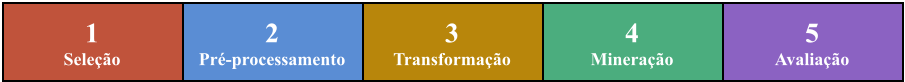

| 1 Seleção | 2 Pré-processamento | 3 Transformação | 4 Mineração | 5 Avaliação |
|-------------|-----------------------|-------------------|---------------|---------------|

### Dataset: ENEM 2025 - Rio Grande do Norte

Os dados utilizados nesta aula são os microdados do ENEM 2025 disponibilizados pelo INEP, já filtrados para o RN. O arquivo de resultados contém registros de todos os candidatos inscritos, independentemente de ter comparecido ou não à prova.

| Quantidade | Descrição |
|--------------|-----------------------------------------------------------|
| 30.449 | Registros de candidatos no arquivo |
| 70 | Colunas disponíveis nos microdados |
| 4.938 | Escolas no catálogo RN |
| 25.965 | Candidatos presentes nos dois dias |
| 5 | Notas disponíveis por candidato (CN, CH, LC, MT, Redação) |

### Passo 1 - Seleção

Antes de qualquer tratamento, precisamos definir qual pergunta queremos responder - porque é ela que determina quais dados selecionar. Sem uma pergunta clara, corremos o risco de selecionar dados de forma oportunista e chegar a padrões espúrios.

### PROBLEMA DE PESQUISA DESTA AULA

"Conseguimos prever o nível de desempenho de um aluno do ENEM 2025 (RN) com base nas notas das provas objetivas e no perfil da escola?"

Com a pergunta definida, selecionamos apenas os dados que a respondem. Dos 70 atributos disponíveis, a maioria é irrelevante: gabaritos, sequências de respostas, códigos de prova. A seleção também envolve filtro de registros: candidatos ausentes não têm notas significativas. Mantemos apenas os 25.965 presentes nos dois dias de prova.

### Colunas selecionadas

- CO\_ESCOLA - chave para join com o catálogo de escolas
- NO\_MUNICIPIO\_ESC - município da escola
- TP\_DEPENDENCIA\_ADM\_ESC - 1=Federal, 2=Estadual, 3=Municipal, 4=Privada
- TP\_LOCALIZACAO\_ESC - 1=Urbana, 2=Rural
- NU\_NOTA\_CN / CH / LC / MT / REDACAO - as cinco notas

### passo1\_selecao.py pandas · merge · filtragem condicional

📄

In [ ]:
# Filtro de presença completa (operador bitwise &)
presenca_completa = (
    (df_raw["TP_PRESENCA_CN"] == 1) &
    (df_raw["TP_PRESENCA_CH"] == 1) &
    (df_raw["TP_PRESENCA_LC"] == 1) &
    (df_raw["TP_PRESENCA_MT"] == 1)
)
df_presentes = df_raw[presenca_completa].copy()

# Enriquecer com nome da escola (left join mantém candidatos sem escola)
df_sel = df_presentes[COLUNAS].merge(df_cat, on="CO_ESCOLA", how="left")

### CONCEITO-CHAVE: VIÉS DE SELEÇÃO

Ao filtrar apenas alunos presentes, excluímos os ausentes. Isso é correto para o nosso problema, mas cria um viés: o modelo aprende sobre quem faz a prova, não sobre quem se inscreve. Essa limitação deve ser documentada.

Saída: dados\_selecionados.csv com 25.965 registros e 11 colunas.

### Passo 2 - Pré-processamento

Dados do mundo real sempre contêm imperfeições. O pré-processamento não é uma etapa 'fácil' - decisões erradas aqui contaminam todas as etapas subsequentes e podem invalidar completamente os resultados do modelo.

### Problemas identificados e estratégias adotadas

### PROBLEMA A - NOTAS ZERO SUSPEITAS

Candidatos presentes com nota zero nas provas objetivas são estatisticamente improváveis (a TRI do ENEM dificilmente converge para zero). Esses zeros são tratados como NaN - ausência de informação confiável, não desempenho real.

### PROBLEMA B - NAN EM NOTAS

Para classificação supervisionada, não imputamos notas de alunos presentes (seria fabricar dados). Removemos esses registros. Perda aceitável: menor que 15% do conjunto selecionado.

### PROBLEMA C - ESCOLAS SEM MATCH NO CATÁLOGO

Mantemos o registro, mas sinalizamos com 'Escola não identificada'. O código da escola ainda é útil como atributo de agrupamento.

📄

### passo2\_preprocessamento.py pandas · numpy · matplotlib

In [ ]:
# Substituir zeros por NaN (candidatos presentes com nota inválida)
for col in NOTAS:
    df[col] = df[col].replace(0, np.nan)

# Remover registros com qualquer nota ausente
df_clean = df.dropna(subset=NOTAS).copy()

# Verificar e remover duplicatas
if df_clean.duplicated().sum():
    df_clean = df_clean.drop_duplicates()

### ARMADILHA: IMPUTAÇÃO INGÊNUA

Substituir notas ausentes pela média da turma cria um efeito de 'ruim'. Para dados de avaliação, remoção é geralmente preferível quando a porcentagem de ausentes é baixa.

Saída: dados\_preprocessados.csv com dados limpos e notas garantidamente válidas.

### Passo 3 - Transformação

Algoritmos de ML não entendem 'escola estadual' ou 'área rural' como texto - precisam de números. Além disso, features bem definidas carregam mais informação do que os atributos brutos originais.

### Atributos derivados criados

- MEDIA\_OBJETIVAS - média aritmética das 4 provas objetivas
- MEDIA\_GERAL - média ponderada igualitária das 5 provas (inclui redação)
- DESVIO\_NOTAS - desvio-padrão das notas do aluno (mede consistência entre áreas)
- MELHOR\_AREA / PIOR\_AREA - área com maior e menor nota (codificadas numericamente)
- LOCALIZACAO\_RURAL - binária: 1 se escola rural, 0 se urbana

### Variável-alvo: NIVEL\_DESEMPENHO

Baseada na MEDIA\_GERAL. Os cortes abaixo refletem a escala do ENEM: abaixo de 400 raramente indica proficiência suficiente para acesso ao Ensino Superior; acima de 700, o candidato compete em cursos mais concorridos.

| Nível | Média Geral | % Candidatos | Cor de referência |
|--------------|---------------|----------------|---------------------|
| Insuficiente | < 400 | ~8% | |
| Regular | 400-549 | ~38% | |
| Bom | 550-699 | ~41% | |
| Excelente | ≥ 700 | ~13% | |

📄

### passo3\_transformacao.py pandas · sklearn.preprocessing · matplotlib

In [ ]:
# Atributos derivados numéricos
df["MEDIA_GERAL"]   = (df[NOTAS_OBJ].sum(axis=1) + df["NU_NOTA_REDACAO"]) / 5
df["DESVIO_NOTAS"] = df[NOTAS_TODAS].std(axis=1)

# Variável-alvo por corte (pd.cut)
df["NIVEL_DESEMPENHO"] = pd.cut(
    df["MEDIA_GERAL"],
    bins=[0, 400, 550, 700, 1001],
    labels=["Insuficiente", "Regular", "Bom", "Excelente"],
    right=False
)

# One-Hot Encoding para tipo de escola (evita ordinalidade implícita)
dummies = pd.get_dummies(df["TIPO_ESCOLA"], prefix="ESCOLA")

# Normalização Min-Max (para KNN e outros algoritmos sensíveis à escala)
scaler = MinMaxScaler()
df_norm[...] = scaler.fit_transform(df[COLUNAS_NORM])

POR QUE ONE-HOT E NÃO LABEL ENCODING? Label Encoding atribui números às categorias (1=Federal, 2=Estadual...), implicando uma ordem que não existe. One-Hot trata cada tipo como binário independente - matematicamente correto para variáveis nominais como tipo de escola. Label Encoding imagina isso: Estadual ←1→ Federal ←1→ Municipal ←1→ Privada One-Hot não impõe nenhuma distância: Estadual = [1, 0, 0, 0] Federal = [0, 1, 0, 0] Municipal = [0, 0, 1, 0] Privada = [0, 0, 0, 1]